In [3]:
print("Program is developed by",u"\u092A\u094D\u0930\u093F\u092F\u093E\u0902\u0936\u0941\u0020\u092E\u093F\u0936\u094D\u0930\u093E")
print("Program is checked by",u"\u0935\u0948\u0936\u093E\u0932\u0940\u0020\u0907\u0902\u0917\u0933\u0947 / \u0936\u094d\u0935\u0947\u0924\u093e \u0935\u093e\u0928\u0916\u0947\u0921\u093c\u0947")
print("Date of performance - 18 Aug 2026")

Program is developed by प्रियांशु मिश्रा
Program is checked by वैशाली इंगळे / श्वेता वानखेड़े
Date of performance - 18 Aug 2026


In [107]:
from collections import deque
import numpy as np
import time
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

In [109]:
# 0 represents an open path, 1 represents a wall
maze = [
    [0, 0, 0, 1, 0, 0, 0, 0],
    [0, 1, 0, 1, 0, 1, 1, 0],
    [0, 1, 0, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 1, 0, 1, 0],
    [0, 0, 0, 0, 1, 0, 0, 0],
    [1, 1, 1, 0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 0]
]

start_node = (0, 0)
goal_node = (7, 7)

def get_neighbors(grid, node):
    """Returns valid, unvisited neighbors (Up, Down, Left, Right)."""
    r, c = node
    neighbors = []
    directions = [(1, 0), (-1, 0), (0, 1), (0, -1)]
    
    for dr, dc in directions:
        nr, nc = r + dr, c + dc
        if 0 <= nr < len(grid) and 0 <= nc < len(grid[0]) and grid[nr][nc] == 0:
            neighbors.append((nr, nc))
    return neighbors

In [110]:
def bfs(grid, start, goal):
    start_time = time.perf_counter()
    queue = deque([(start, [start])])
    visited = set([start])
    history = [] # Tracks the exact order we visit nodes
    
    while queue:
        current, path = queue.popleft()
        history.append(current) # Record the traversal
        
        if current == goal:
            return path, len(history), (time.perf_counter() - start_time), history
            
        for neighbor in get_neighbors(grid, current):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append((neighbor, path + [neighbor]))
                
    return None, len(history), (time.perf_counter() - start_time), history

In [111]:
def dfs(grid, start, goal):
    start_time = time.perf_counter()
    stack = [(start, [start])]
    visited = set([start])
    history = [] # Tracks the exact order we visit nodes
    
    while stack:
        current, path = stack.pop()
        history.append(current) # Record the traversal
        
        if current == goal:
            return path, len(history), (time.perf_counter() - start_time), history
            
        for neighbor in get_neighbors(grid, current):
            if neighbor not in visited:
                visited.add(neighbor)
                stack.append((neighbor, path + [neighbor]))
                
    return None, len(history), (time.perf_counter() - start_time), history

In [112]:
def animate_traversal(grid, history, final_path, title="Traversal"):
    """Animates the exploration history of the algorithm."""
    rows, cols = len(grid), len(grid[0])
    
    for i in range(1, len(history) + 1):
        img = np.ones((rows, cols, 3)) # White background
        
        # 1. Draw walls (Black)
        for r in range(rows):
            for c in range(cols):
                if grid[r][c] == 1:
                    img[r, c] = [0, 0, 0] 
                    
        # 2. Draw the area explored so far (Orange)
        for r, c in history[:i]:
            img[r, c] = [1.0, 0.8, 0.4] 
            
        # 3. If it's the final frame, overlay the final chosen path (Blue)
        if i == len(history) and final_path:
            for r, c in final_path:
                img[r, c] = [0.2, 0.6, 1.0] 
                
        # 4. Draw Start (Green) and Goal (Red)
        img[start_node[0], start_node[1]] = [0.0, 0.8, 0.0]
        img[goal_node[0], goal_node[1]] = [0.8, 0.0, 0.0]
        
        # Setup the plot
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.imshow(img)
        ax.set_title(f"{title}\nNodes Explored: {i}", fontsize=14, fontweight='bold')
        ax.set_xticks(np.arange(-.5, cols, 1), minor=True)
        ax.set_yticks(np.arange(-.5, rows, 1), minor=True)
        ax.grid(which="minor", color="gray", linestyle='-', linewidth=2)
        ax.tick_params(which="minor", bottom=False, left=False)
        ax.set_xticks([]) 
        ax.set_yticks([]) 
        
        # This clears the previous frame and displays the new one
        clear_output(wait=True)
        display(fig)
        plt.close(fig)
        time.sleep(0.05) # Delay between frames (adjust to make it faster/slower)

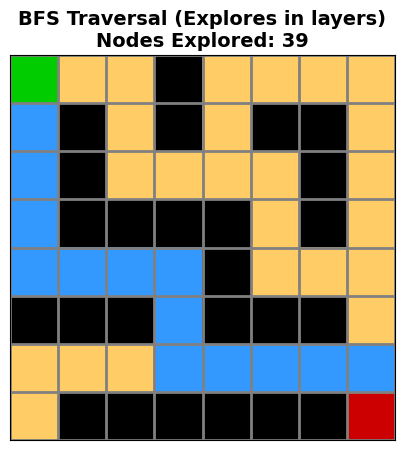

In [130]:
# Execute BFS and capture the history
bfs_path, bfs_nodes, bfs_time, bfs_history = bfs(maze, start_node, goal_node)

# Run the animation
animate_traversal(maze, bfs_history, bfs_path, title="BFS Traversal (Explores in layers)")

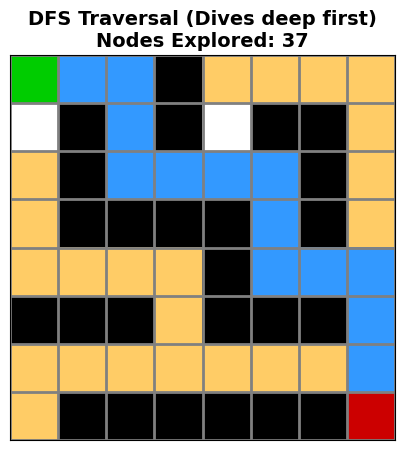

In [132]:
# Execute DFS and capture the history
dfs_path, dfs_nodes, dfs_time, dfs_history = dfs(maze, start_node, goal_node)

# Run the animation
animate_traversal(maze, dfs_history, dfs_path, title="DFS Traversal (Dives deep first)")

In [115]:
# Print the Comparison Report based on the data gathered in previous cells
print("\n" + "="*55)
print(" "*15 + "PERFORMANCE COMPARISON")
print("="*55)
print(f"{'Metric':<20} | {'BFS (Queue)':<15} | {'DFS (Stack)':<15}")
print("-" * 55)
print(f"{'Path Length':<20} | {len(bfs_path):<15} | {len(dfs_path):<15}")
print(f"{'Nodes Explored':<20} | {bfs_nodes:<15} | {dfs_nodes:<15}")
print(f"{'Execution Time (s)':<20} | {bfs_time:<15.6f} | {dfs_time:<15.6f}")
print("="*55)


               PERFORMANCE COMPARISON
Metric               | BFS (Queue)     | DFS (Stack)    
-------------------------------------------------------
Path Length          | 15              | 15             
Nodes Explored       | 39              | 37             
Execution Time (s)   | 0.000102        | 0.000155       


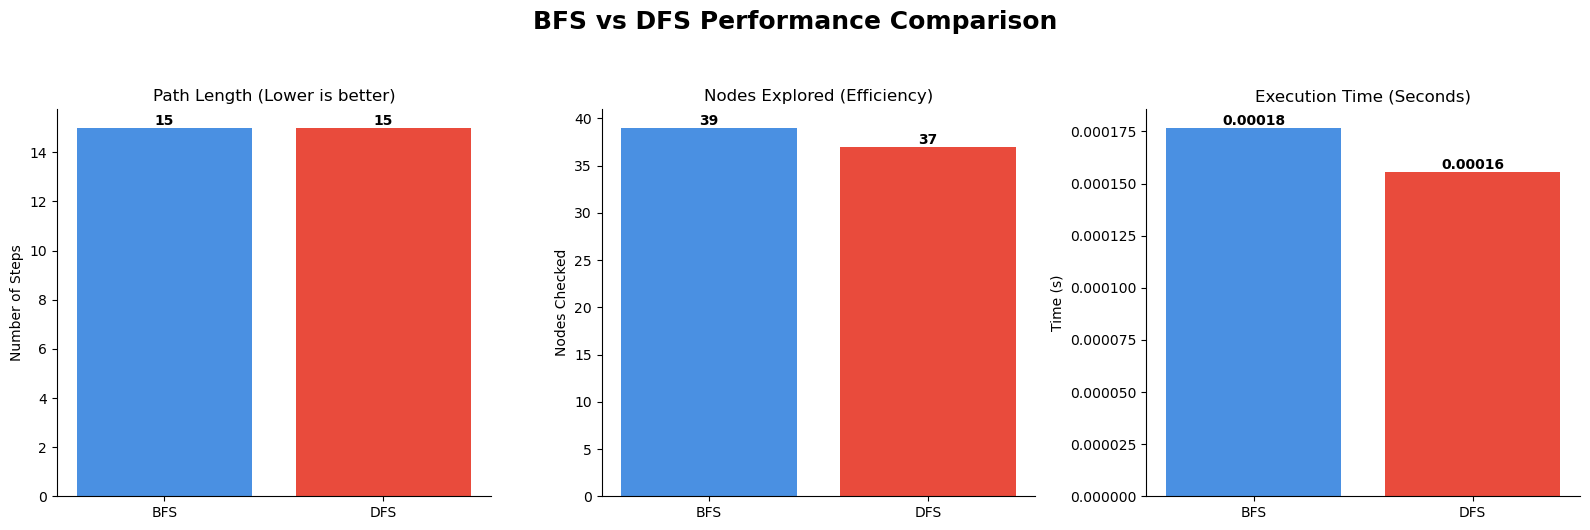

In [128]:
# Extract the data we gathered from running both algorithms
metrics = ['Path Length', 'Nodes Explored', 'Execution Time (s)']
bfs_data = [len(bfs_path), bfs_nodes, bfs_time]
dfs_data = [len(dfs_path), dfs_nodes, dfs_time]

# Set up the figure with 3 subplots side-by-side
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('BFS vs DFS Performance Comparison', fontsize=18, fontweight='bold', y=1.05)

colors = ['#4A90E2', '#E94B3C'] # Blue for BFS, Red for DFS
labels = ['BFS', 'DFS']

# 1. Path Length Bar Chart
axes[0].bar(labels, [bfs_data[0], dfs_data[0]], color=colors)
axes[0].set_title('Path Length (Lower is better)', fontsize=12)
axes[0].set_ylabel('Number of Steps')

# 2. Nodes Explored Bar Chart
axes[1].bar(labels, [bfs_data[1], dfs_data[1]], color=colors)
axes[1].set_title('Nodes Explored (Efficiency)', fontsize=12)
axes[1].set_ylabel('Nodes Checked')

# 3. Execution Time Bar Chart
axes[2].bar(labels, [bfs_data[2], dfs_data[2]], color=colors)
axes[2].set_title('Execution Time (Seconds)', fontsize=12)
axes[2].set_ylabel('Time (s)')

# Add the exact numbers on top of each bar for clarity
for i, ax in enumerate(axes):
    ax.text(0, bfs_data[i], f'{bfs_data[i]:.5f}' if i == 2 else str(bfs_data[i]), 
            ha='center', va='bottom', fontweight='bold')
    ax.text(1, dfs_data[i], f'{dfs_data[i]:.5f}' if i == 2 else str(dfs_data[i]), 
            ha='center', va='bottom', fontweight='bold')
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()